# Evaluation Metrics for Downscaling Models

## Setup

Set `REPO_ROOT` and `CONFIG_PATH` paths according to your local repository structure.  

Set `OUTPUT_DIR` to specify where output figures and tables are saved.

In [1]:
from pathlib import Path
import sys

import xarray as xr

xr.set_options(
    display_expand_data=False,
    display_expand_attrs=False,
)

In [ ]:
REPO_ROOT = Path.home() / "projects" / "dl-downscaling-evaluation-ec"
CONFIG_PATH = REPO_ROOT / "config" / "config.yaml"

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

OUTPUT_DIR = REPO_ROOT / "outputs" 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [ ]:
from src.io import load_config, load_dataset_series


config = load_config(CONFIG_PATH)

years = range(
    config["years"]["start"],
    config["years"]["end"] + 1
)

datasets = {
    "reference": None,
    "models": {}
}


print("\n[INFO] Loading reference dataset")

datasets["reference"] = load_dataset_series(
    config["reference"],
    years,
    lazy=False
)


print("\n[INFO] Loading model output datasets")

for model_name, cfg in config["models"].items():

    print(f"\n[INFO] Loading {model_name}")

    datasets["models"][model_name] = load_dataset_series(
        cfg,
        years,
        lazy=False
    )

### Datasets consistency

In [4]:
from src.io import check_spatiotemporal_compatibility

reference = datasets["reference"]

for model_name, da in datasets["models"].items():

    print(f"\n[INFO] Checking {model_name}")
    check_spatiotemporal_compatibility(reference, da)


[INFO] Checking ERA5-DownGAN-EC
  time: True
  lat:  True
  lon:  True

[INFO] Checking cGAN-U-Net-EC
  time: True
  lat:  True
  lon:  True

[INFO] Checking DDIM-EC
  time: True
  lat:  True
  lon:  True


In [5]:
datasets['models']['cGAN-U-Net-EC']

<xarray.DataArray 'T_2M' (time: 3650, rlat: 405, rlon: 418)> Size: 2GB
287.1 287.0 287.0 287.0 287.0 287.0 ... 246.5 247.0 247.6 248.3 247.5 247.5
Coordinates:
  * time     (time) object 29kB 2005-01-01 11:30:00 ... 2014-12-31 11:30:00
  * rlat     (rlat) float64 3kB -23.05 -22.93 -22.83 -22.72 ... 21.17 21.28 21.4
  * rlon     (rlon) float64 3kB -28.05 -27.93 -27.83 -27.72 ... 17.6 17.72 17.83
    lon      (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat      (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.64 66.58 66.52
Attributes: (6)

## Compute metrics

In [6]:
from src.metrics import bias, mae, rmse, correlation, compute_grid_metrics

selected_metrics = [
    bias,
    mae,
    rmse,
    correlation,
]

analysis_period = {
    "start_date": "2005-01-01",
    "end_date": "2014-12-31",
}

reference = datasets["reference"]

metrics = {}

for model_name, pred in datasets["models"].items():

    print(f"\n[INFO] Computing metrics for {model_name}")

    metrics[model_name] = compute_grid_metrics(
        pred,
        reference,
        metrics=selected_metrics,
        verbose=True,
        **analysis_period,
    )


[INFO] Computing metrics for ERA5-DownGAN-EC

Summary:

bias          mean= -0.1060   min= -1.7678   max= +1.2483
mae           mean= +1.8719   min= +0.6747   max= +4.3531
rmse          mean= +2.4114   min= +0.8647   max= +5.3063
correlation   mean= +0.9086   min= +0.5233   max= +0.9762


[INFO] Computing metrics for cGAN-U-Net-EC

Summary:

bias          mean= -0.1658   min= -3.5292   max= +3.7730
mae           mean= +1.2494   min= +0.2596   max= +4.0193
rmse          mean= +1.6076   min= +0.3370   max= +4.6782
correlation   mean= +0.9753   min= +0.8696   max= +0.9963


[INFO] Computing metrics for DDIM-EC

Summary:

bias          mean= -0.0305   min= -5.4522   max= +8.0992
mae           mean= +1.2719   min= +0.3990   max= +8.0992
rmse          mean= +1.6595   min= +0.4996   max= +8.4133
correlation   mean= +0.9722   min= +0.8326   max= +0.9944



In [7]:
metrics["DDIM-EC"]['bias']

<xarray.DataArray 'T_2M' (rlat: 405, rlon: 418)> Size: 677kB
-4.037 -3.083 -3.468 -3.102 -3.144 -2.982 ... 0.8836 0.7651 0.8125 1.486 2.827
Coordinates:
  * rlat       (rlat) float64 3kB -23.05 -22.93 -22.83 ... 21.17 21.28 21.4
  * rlon       (rlon) float64 3kB -28.05 -27.93 -27.83 ... 17.6 17.72 17.83
    lon        (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat        (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.58 66.52
    height_2m  float32 4B 2.0
Attributes: (4)

## Compute percentiles

In [8]:
from src.statistics import compute_grid_percentiles


percentiles = (5, 50, 95)


percentile_fields = {}


print(f"[INFO] Computing reference percentiles")
percentile_fields["reference"] = compute_grid_percentiles(
    datasets["reference"],
    percentiles=percentiles,
)


for model_name, da in datasets["models"].items():

    print(f"[INFO] Computing percentiles for {model_name}")

    percentile_fields[model_name] = compute_grid_percentiles(
        da,
        percentiles=percentiles,
    )

[INFO] Computing reference percentiles
[INFO] Computing percentiles for ERA5-DownGAN-EC
[INFO] Computing percentiles for cGAN-U-Net-EC
[INFO] Computing percentiles for DDIM-EC


In [9]:
percentile_fields["reference"]["p50"]

<xarray.DataArray 'T_2M' (rlat: 405, rlon: 418)> Size: 1MB
301.2 301.2 301.2 301.2 301.3 301.3 ... 272.4 272.6 272.9 272.7 271.5 270.5
Coordinates:
  * rlat      (rlat) float64 3kB -23.05 -22.93 -22.83 ... 21.17 21.28 21.4
  * rlon      (rlon) float64 3kB -28.05 -27.93 -27.83 ... 17.6 17.72 17.83
    lon       (rlat, rlon) float32 677kB -9.904 -9.803 -9.702 ... 63.47 63.68
    lat       (rlat, rlon) float32 677kB 22.41 22.45 22.49 ... 66.64 66.58 66.52
    quantile  float64 8B 0.5
Attributes: (6)

## Panel plot

In [10]:
from src.plotting import plot_metrics_panel

PLOT_CONFIG_PATH = REPO_ROOT / "config" / "plot_config.yaml"

plot_config = load_config(PLOT_CONFIG_PATH)

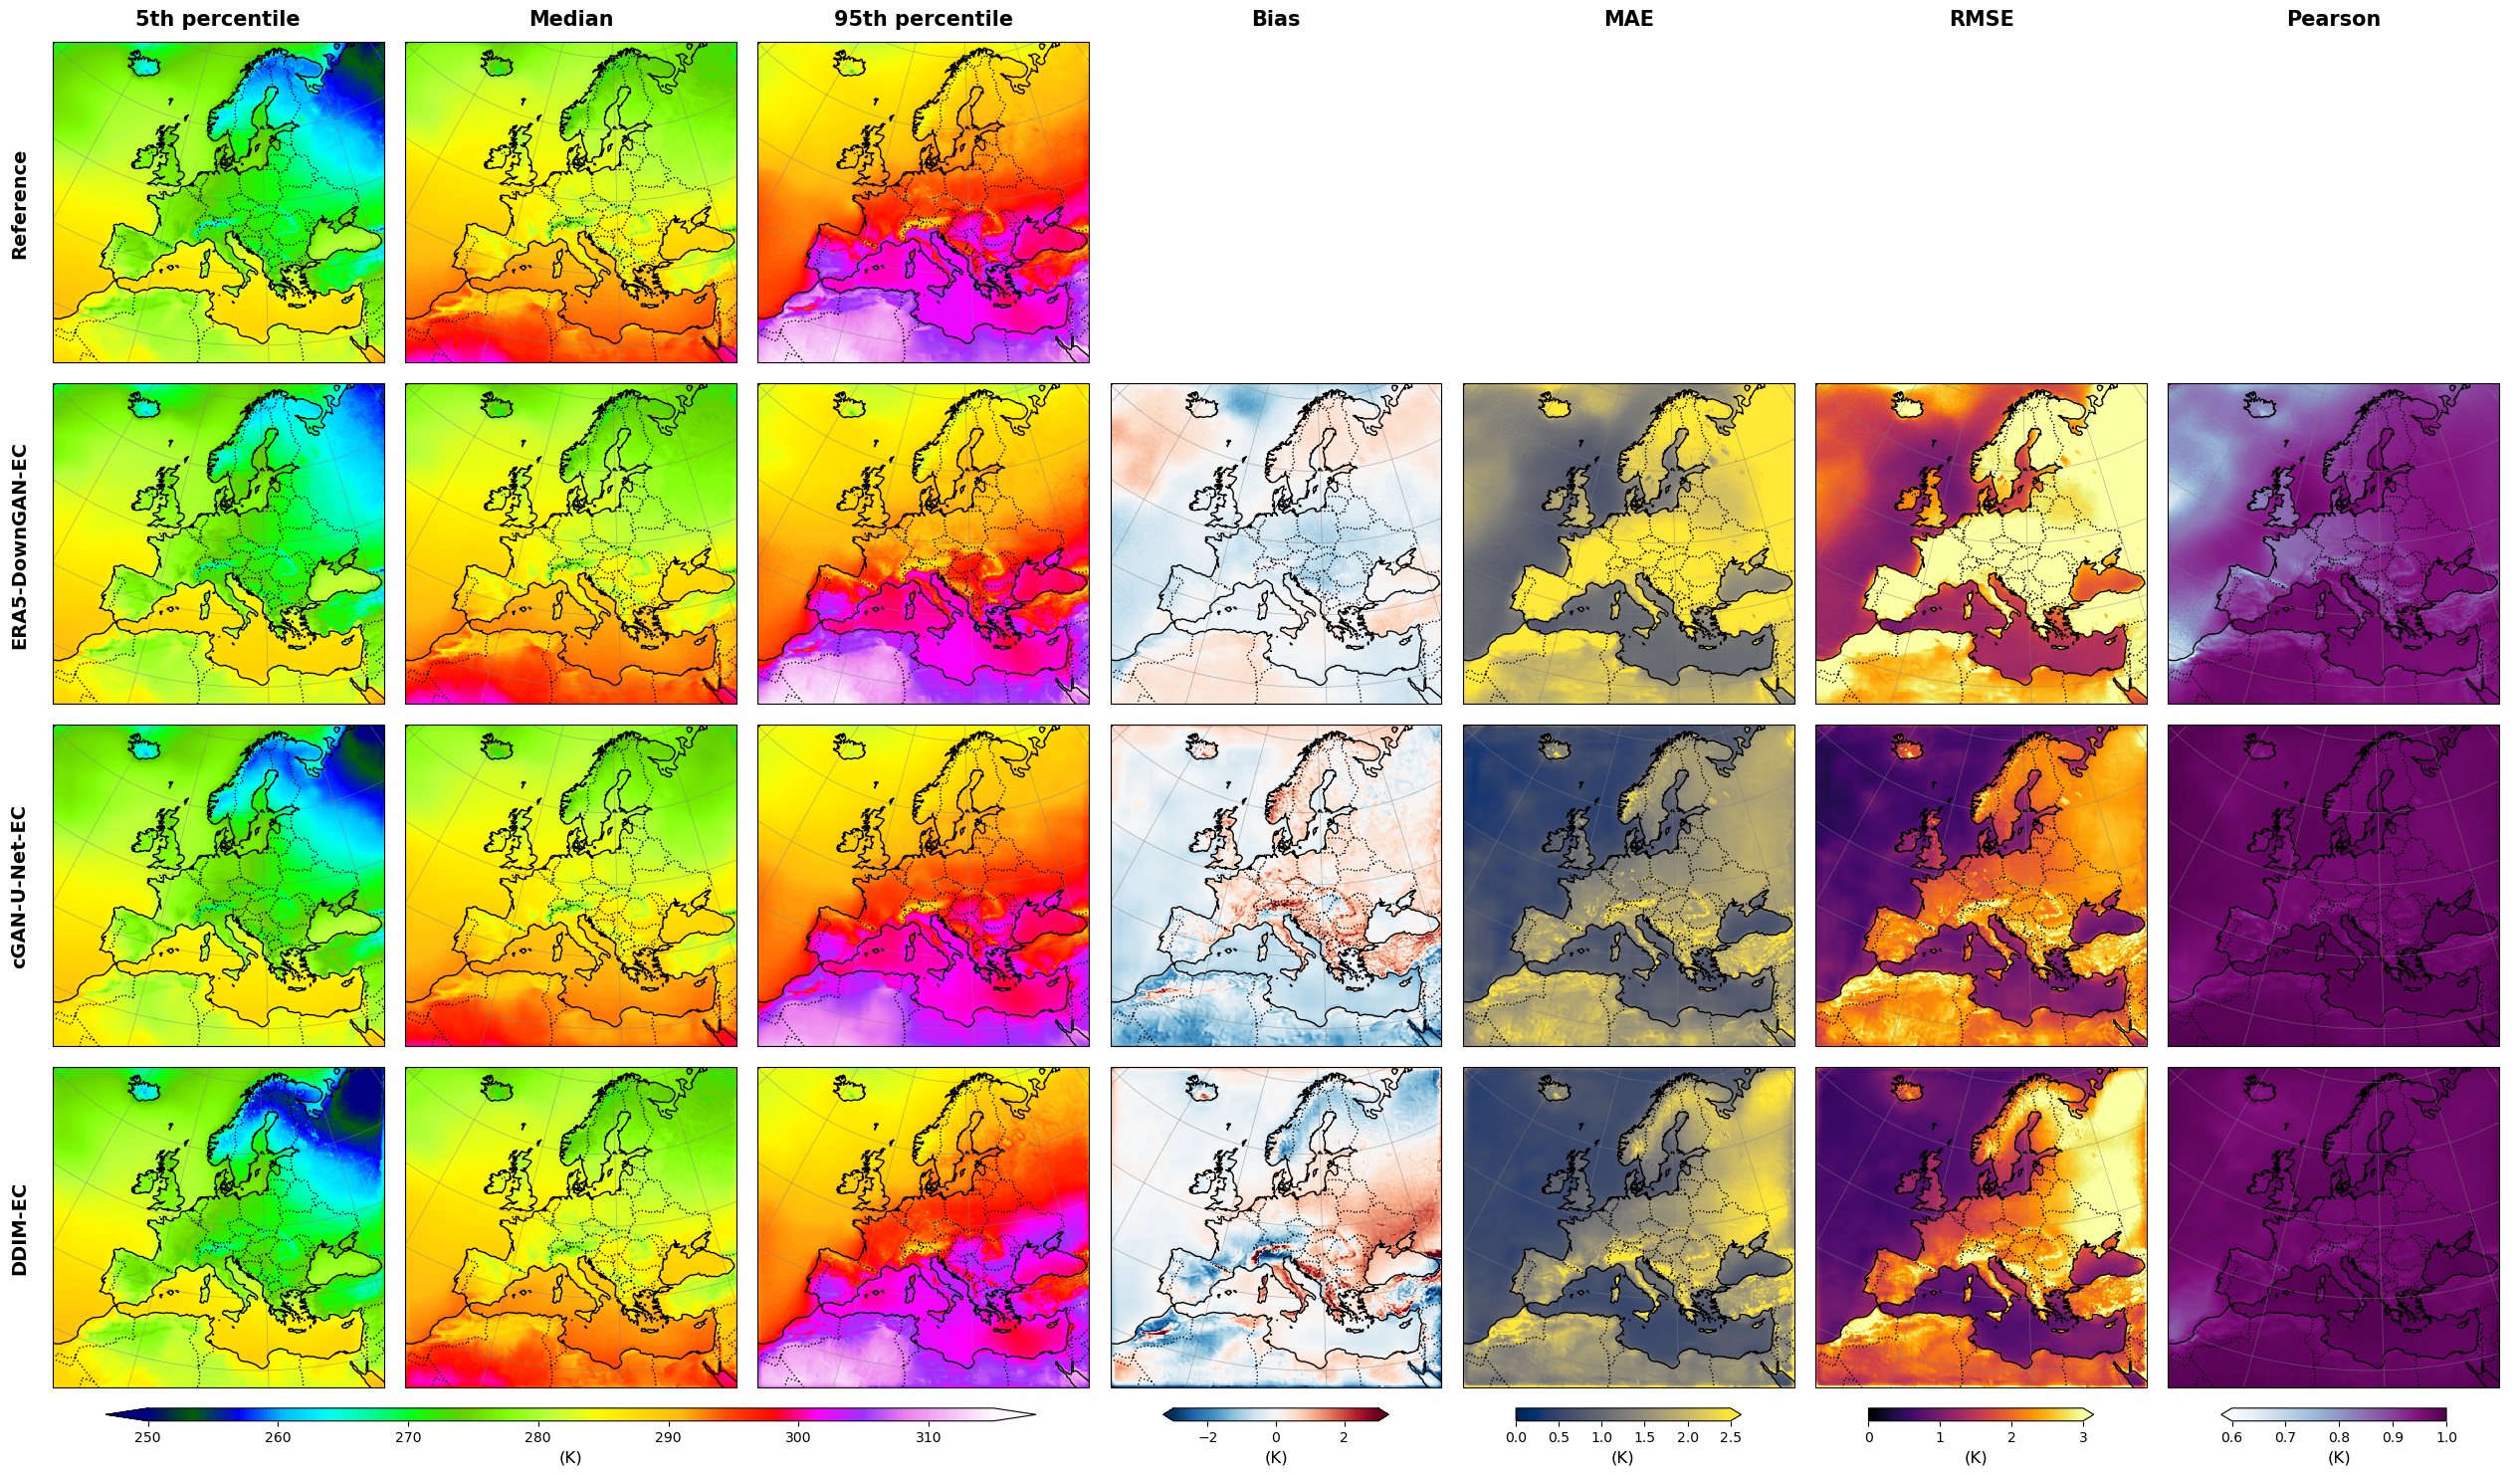

In [11]:
fig, axes, images = plot_metrics_panel(
    metrics,
    percentile_fields,
    plot_config
)

In [12]:
fig.savefig(
    OUTPUT_DIR / "metrics_panel.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "metrics_panel.pdf",
    bbox_inches="tight"
)

## Metrics summary

In [13]:
from src.metrics import summarize_metric_distributions

df_summary = summarize_metric_distributions(metrics)

df_summary

,model,metric,min,max,p1,p5,p50,p95,p99
0,ERA5-DownGAN-EC,bias,-1.767825,1.248289,-1.147208,-0.774211,-0.122684,0.560625,0.799790
1,ERA5-DownGAN-EC,mae,0.674668,4.353074,0.776992,0.881273,1.923990,2.967762,3.370347
2,ERA5-DownGAN-EC,rmse,0.864691,5.306297,0.988895,1.109658,2.491899,3.806541,4.412250
3,ERA5-DownGAN-EC,correlation,0.523319,0.976188,0.732609,0.796059,0.928771,0.967775,0.971596
4,cGAN-U-Net-EC,bias,-3.529155,3.773032,-1.752329,-1.229286,-0.182858,0.885131,1.571266
5,cGAN-U-Net-EC,mae,0.259625,4.019284,0.338639,0.432715,1.356767,2.077893,2.408957
6,cGAN-U-Net-EC,rmse,0.336998,4.678248,0.429921,0.575299,1.784055,2.606366,3.013340
7,cGAN-U-Net-EC,correlation,0.869612,0.996328,0.944062,0.957225,0.975753,0.990247,0.992639
8,DDIM-EC,bias,-5.452236,8.099176,-2.143475,-1.233050,-0.046589,1.215267,1.818737
9,DDIM-EC,mae,0.399025,8.099176,0.445752,0.500522,1.272467,2.343214,2.763258


In [14]:
df_summary.to_csv(
    OUTPUT_DIR / "metric_distribution_summary.csv",
    index=False,
)

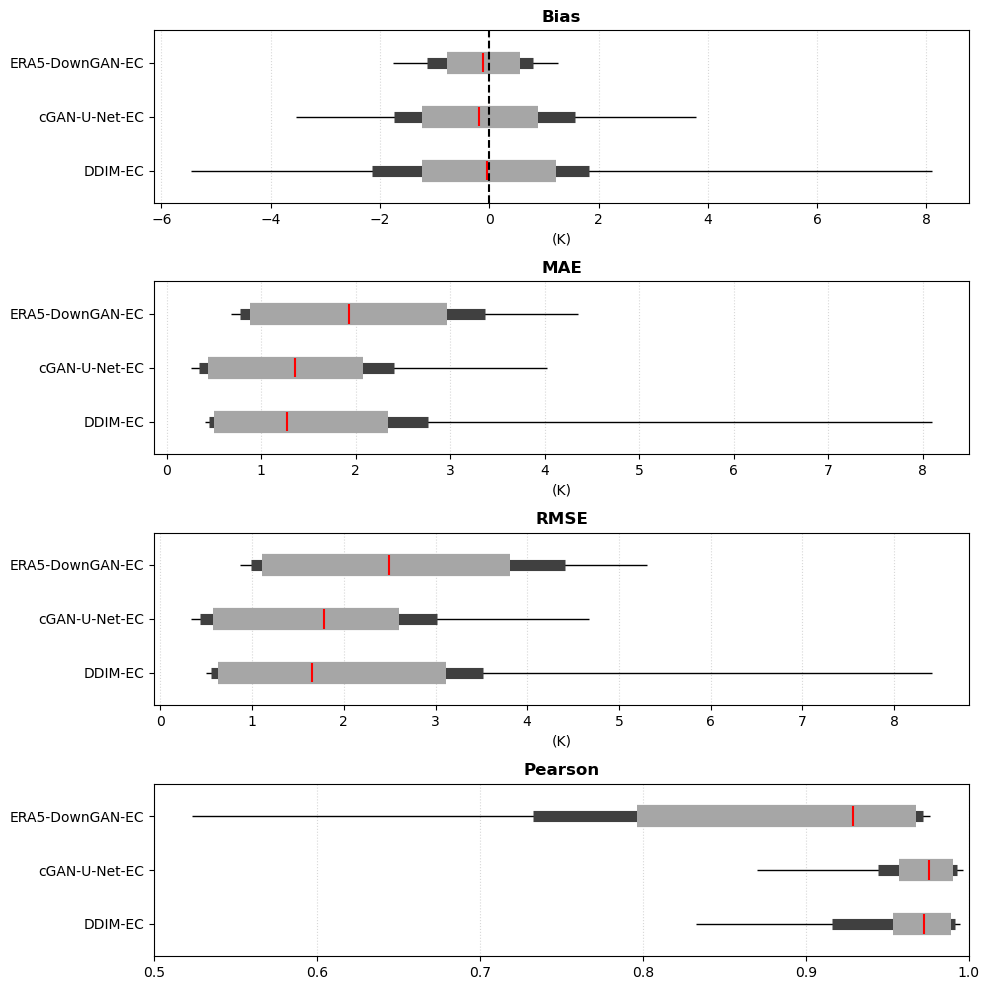

In [15]:
from src.plotting import plot_metric_summary

fig, ax = plot_metric_summary(df_summary)

In [16]:
fig.savefig(
    OUTPUT_DIR / "metrics_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "metrics_distribution.pdf",
    bbox_inches="tight"
)